# MATE dataset preparation and analysis

MATE is an external benchmark for mathematical word problem answerability. This notebook verifies the corrected raw CSV, removes complete pairs that share question text with UMWP, and validates the retained evaluation set against all four fixed comparison files.

## 1. Load and verify the raw dataset

Use the raw SHA-256 recorded in [PROJECT_CONTEXT.md](../PROJECT_CONTEXT.md). Read all fields as strings so original question text and metadata, including empty categories, survive the CSV round trip.

In [1]:
import csv
import hashlib
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "PROJECT_CONTEXT.md").is_file() and (path / "src").is_dir()
)
RAW_PATH = PROJECT_ROOT / "data/raw/mate/MATE Dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/mate"
RAW_COLUMNS = ["pair_id", "text", "label", "source", "category"]
LABEL_TO_ID = {"ANSWERABLE": 0, "UNANSWERABLE": 1}
COMPARISONS = {
    "SUM train": "data/processed/sum/train.csv",
    "SUM validation": "data/processed/sum/validation.csv",
    "SUM test": "data/processed/sum/test.csv",
    "UMWP test": "data/processed/umwp/test.csv",
}


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_csv(path):
    with path.open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.reader(handle, strict=True)
        columns = next(reader)
        assert len(columns) == len(set(columns)), f"Duplicate columns in {path}"
        rows = list(reader)
    assert all(len(row) == len(columns) for row in rows), f"Ragged records in {path}"
    return pd.DataFrame(rows, columns=columns)


context = (PROJECT_ROOT / "PROJECT_CONTEXT.md").read_text(encoding="utf-8")
recorded_hash = re.search(r"SHA-256 of the audited raw bytes is `([a-f0-9]{64})`", context)
assert recorded_hash, "The recorded raw MATE SHA-256 is missing."
raw_hash = sha256(RAW_PATH)
assert raw_hash == recorded_hash.group(1), "Raw MATE SHA-256 differs from the recorded value."
raw = read_csv(RAW_PATH)
assert raw.columns.tolist() == RAW_COLUMNS, "Unexpected raw MATE schema."
print(f"Verified raw MATE SHA-256: {raw_hash}")
display(raw.head(3))

Verified raw MATE SHA-256: e2cfd8dd2cf9cb2761f68d148765e455f0cdc2cf37bfc61224e4de892e494e52


,pair_id,text,label,source,category
0,1,A certain cuboid has a volume of 28/3 cubic ce...,ANSWERABLE,DMath,
1,1,A certain cuboid has a volume of an unspecifie...,UNANSWERABLE,DMath,1
2,2,If the average (arithmetic mean) of five conse...,ANSWERABLE,AQuA-RAT,


## 2. Identify UMWP overlaps and exclude whole pairs

Check literal question strings and normalized strings. Normalization applies Unicode NFKC, case folding and whitespace collapsing for comparison only. When either question in a MATE pair matches UMWP, remove both questions to preserve complete pairs and class balance. The exclusion ledger labels each matched pair as exact, normalized-only, or both if it contains triggers of each type.

In [2]:
def normalize(text):
    normalized = unicodedata.normalize("NFKC", text).casefold()
    return " ".join(normalized.split())


def overlap_masks(questions, comparison):
    exact = questions.isin(set(comparison))
    normalized = questions.map(normalize).isin(set(comparison.map(normalize)))
    assert (normalized | ~exact).all(), "An exact match disappeared after normalization."
    return exact, normalized


comparison_texts = {
    name: read_csv(PROJECT_ROOT / relative_path)["text"]
    for name, relative_path in COMPARISONS.items()
}
exact, normalized = overlap_masks(raw["text"], comparison_texts["UMWP test"])
normalized_only = normalized & ~exact
assert (int(exact.sum()), int(normalized_only.sum())) == (179, 28), "Unexpected UMWP overlap counts."

triggers = raw.loc[normalized, ["pair_id"]].assign(
    exact=exact[normalized], normalized_only=normalized_only[normalized]
)
excluded_pairs = triggers.groupby("pair_id", sort=False).sum().reset_index()
excluded_pairs = excluded_pairs.rename(columns={
    "exact": "exact_match_rows",
    "normalized_only": "normalized_only_match_rows",
})
excluded_pairs["reason"] = [
    "umwp_exact_and_normalized_only" if exact_count and normalized_count
    else "umwp_exact" if exact_count else "umwp_normalized_only"
    for exact_count, normalized_count in zip(
        excluded_pairs["exact_match_rows"], excluded_pairs["normalized_only_match_rows"]
    )
]
exclude = raw["pair_id"].isin(excluded_pairs["pair_id"])
assert len(excluded_pairs) == 207, "Expected 207 excluded MATE pairs."
assert int(exclude.sum()) == 414, "Expected 414 excluded MATE rows."

retained = raw.loc[~exclude].reset_index(drop=True)
processed = retained.assign(label_id=retained["label"].map(LABEL_TO_ID))
processed.insert(0, "id", range(1, len(processed) + 1))
display(pd.Series({
    "Exact UMWP matches": int(exact.sum()),
    "Additional normalized-only matches": int(normalized_only.sum()),
    "Excluded MATE pairs": len(excluded_pairs),
    "Excluded MATE rows": int(exclude.sum()),
}, name="Count").to_frame())

,Count
Exact UMWP matches,179
Additional normalized-only matches,28
Excluded MATE pairs,207
Excluded MATE rows,414


## 3. Validate the benchmark

After filtering, assign sequential integer row IDs in retained file order. The first column, id, identifies each question, while pair_id preserves the original pair membership. The label column keeps the same strings as processed SUM and UMWP. The companion `label_id` column records the mapping ANSWERABLE = 0 and UNANSWERABLE = 1. Empty categories are expected for ANSWERABLE rows. Source and category are audit metadata, while question text is the model input.

In [3]:
def validate_pairs(frame, expected_rows, expected_pairs):
    required = ["pair_id", "text", "label", "source"]
    for column in required:
        assert frame[column].map(lambda value: bool(value.strip())).all(), f"Missing {column}."
    assert len(frame) == expected_rows, "Unexpected row count."
    assert frame["pair_id"].nunique() == expected_pairs, "Unexpected pair count."
    assert frame["label"].value_counts().to_dict() == dict.fromkeys(LABEL_TO_ID, expected_pairs), (
        "Unexpected class labels or counts."
    )
    pair_labels = pd.crosstab(frame["pair_id"], frame["label"])
    assert pair_labels.eq(1).all().all(), "Each pair must contain exactly one row per label."
    assert frame.groupby("pair_id")["source"].nunique().eq(1).all(), "Inconsistent pair source."
    assert frame.loc[frame["label"].eq("ANSWERABLE"), "category"].eq("").all(), (
        "Expected empty categories for ANSWERABLE rows."
    )
    assert frame.loc[frame["label"].eq("UNANSWERABLE"), "category"].isin(list("12345")).all(), (
        "Missing or unexpected UNANSWERABLE category."
    )
    for method, text_keys in (("exact", frame["text"]), ("normalized", frame["text"].map(normalize))):
        assert frame.groupby(text_keys)["label"].nunique().le(1).all(), f"Conflicting {method} labels."
        assert text_keys.is_unique, f"Duplicate {method} question texts."


validate_pairs(raw, expected_rows=10000, expected_pairs=5000)
validate_pairs(processed, expected_rows=9586, expected_pairs=4793)
pd.testing.assert_frame_equal(processed[RAW_COLUMNS], retained)
assert processed.columns[0] == "id", "Row ID must be the first column."
assert pd.api.types.is_integer_dtype(processed["id"]), "Row IDs must be integers."
assert processed["id"].is_unique, "Duplicate row IDs."
assert processed["id"].tolist() == list(range(1, 9587)), "Expected sequential IDs from 1 to 9586."
assert processed["label_id"].notna().all(), "Missing numeric labels."

overlap_rows = []
for name, comparison in comparison_texts.items():
    raw_exact, raw_normalized = overlap_masks(raw["text"], comparison)
    final_exact, final_normalized = overlap_masks(processed["text"], comparison)
    counts = (int(final_exact.sum()), int(final_normalized.sum()))
    assert counts == (0, 0), f"Unexpected retained MATE overlap with {name}: {counts}."
    overlap_rows.append((name, int(raw_exact.sum()), int(raw_normalized.sum()), *counts))

display(pd.DataFrame(overlap_rows, columns=[
    "Comparison", "Raw exact", "Raw normalized", "Retained exact", "Retained normalized",
]).set_index("Comparison"))
print("PASS: sequential row IDs, complete balanced pairs, required values, unique texts and zero retained overlaps.")

,Raw exact,Raw normalized,Retained exact,Retained normalized
Comparison,,,,
SUM train,0,0,0,0
SUM validation,0,0,0,0
SUM test,0,0,0,0
UMWP test,179,207,0,0


PASS: sequential row IDs, complete balanced pairs, required values, unique texts and zero retained overlaps.


## 4. Dataset size, class balance and question lengths

Word counts use whitespace splitting, as in the SUM analysis. This provides a descriptive length comparison without loading a tokenizer.

,Rows,Pairs,ANSWERABLE,UNANSWERABLE,Share of raw rows (%)
Raw,10000,5000,5000,5000,100.00
Excluded,414,207,207,207,4.14
Retained,9586,4793,4793,4793,95.86


,mean,50%,min,max
Raw,37.58,35.0,1.0,179.0
Excluded,46.29,42.0,14.0,118.0
Retained,37.21,35.0,1.0,179.0


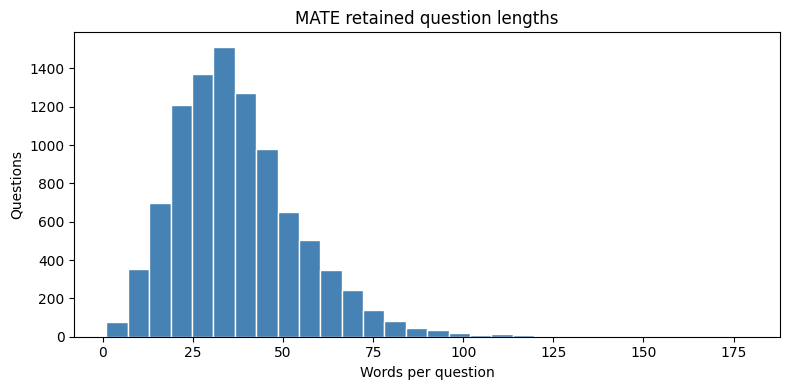

In [4]:
cohorts = {"Raw": raw, "Excluded": raw.loc[exclude], "Retained": processed}
size_table = pd.DataFrame.from_dict({
    name: {
        "Rows": len(frame),
        "Pairs": frame["pair_id"].nunique(),
        "ANSWERABLE": int(frame["label"].eq("ANSWERABLE").sum()),
        "UNANSWERABLE": int(frame["label"].eq("UNANSWERABLE").sum()),
        "Share of raw rows (%)": 100 * len(frame) / len(raw),
    }
    for name, frame in cohorts.items()
}, orient="index")
display(size_table.round(2))

word_counts = {
    name: frame["text"].str.split().str.len()
    for name, frame in cohorts.items()
}
display(pd.DataFrame(word_counts).describe().T[["mean", "50%", "min", "max"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(word_counts["Retained"], bins=30, color="steelblue", edgecolor="white")
ax.set(title="MATE retained question lengths", xlabel="Words per question", ylabel="Questions")
fig.tight_layout()
plt.show()

## 5. Export and verify

Write the validated CSV and a separate pair-level exclusion ledger. Reload both to check field values and row order, then report the SHA-256 of each artifact. For the processed test set, also report the LF-normalized hash used by the shared evaluation loader.

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
outputs = {
    OUTPUT_DIR / "test.csv": processed,
    OUTPUT_DIR / "excluded_pairs.csv": excluded_pairs,
}
for path, frame in outputs.items():
    frame.to_csv(path, index=False, encoding="utf-8", lineterminator="\n")

for path, frame in outputs.items():
    pd.testing.assert_frame_equal(read_csv(path), frame.astype(str))
    print(f"{path.relative_to(PROJECT_ROOT).as_posix()} | {len(frame):,} rows | SHA-256 {sha256(path)}")

test_path = OUTPUT_DIR / "test.csv"
lf_bytes = test_path.read_bytes().replace(b"\r\n", b"\n")
print(f"Processed test SHA-256 (LF-normalized): {hashlib.sha256(lf_bytes).hexdigest()}")

assert sha256(RAW_PATH) == raw_hash, "Raw MATE file changed during preparation."
print("PASS: both exports reload exactly and raw MATE is unchanged.")

data/processed/mate/test.csv | 9,586 rows | SHA-256 377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b0a888d71f6542da5b8
data/processed/mate/excluded_pairs.csv | 207 rows | SHA-256 478e7b5ef5bea2d105b07552d25131d000c69dc3660f34db1cbd5317aea86e19
Processed test SHA-256 (LF-normalized): 377f7a28a6b2a5236ce24eeebc889c99ec38ff92c52c9b0a888d71f6542da5b8
PASS: both exports reload exactly and raw MATE is unchanged.


## Dataset preparation decision

Use the retained 4,793 pairs for MATE external evaluation. The pair-level exclusion was based on overlap with UMWP evaluation data. The text checks detected no MATE overlap with SUM training, validation or test, and no retained overlap with UMWP. These checks do not rule out paraphrases, shared templates or model pretraining exposure. Integration and model evaluation are separate work.